In [ ]:

from google.colab import files

uploaded = files.upload()


Saving England_classifications.csv to England_classifications.csv


In [ ]:
!pip -q install pandas rdflib matplotlib

In [ ]:

import pandas as pd
from pathlib import Path

sources = {
    "classifications": "England_classifications.csv",
    "objectives": "England_objectives.csv",
    "challenges": "England_challenges.csv",
    "protected_areas": "England_waterbody_to_protected_area_links.csv"
}

data = {
    name: pd.read_csv(filename, low_memory=False)
    for name, filename in sources.items()
}

# Kenal pasti water body sungai, bukan groundwater
river_ids = set()

for name in ["classifications", "objectives", "challenges"]:
    df = data[name]
    if "Water Body" in df.columns:
        mask = df["Water Body"].fillna("").str.contains(
            r"\bWharfe\b", case=False, regex=True
        )
        if "Water Body Type" in df.columns:
            mask &= df["Water Body Type"].eq("River")
        river_ids.update(df.loc[mask, "Water Body ID"].dropna())

# Hubungkan rekod menggunakan Water Body ID
filtered = {}

for name, df in data.items():
    filtered[name] = df[
        df["Water Body ID"].isin(river_ids)
    ].copy()

    print(name, len(filtered[name]), "records")

print("Number of water bodies:", len(river_ids))
print("Water Body IDs:", sorted(river_ids))


classifications 8596 records
objectives 1156 records
challenges 152 records
protected_areas 54 records
Number of water bodies: 30
Water Body IDs: ['GB104027063930', 'GB104027063940', 'GB104027063950', 'GB104027063960', 'GB104027063970', 'GB104027063980', 'GB104027063990', 'GB104027064002', 'GB104027064010', 'GB104027064020', 'GB104027064030', 'GB104027064050', 'GB104027064060', 'GB104027064080', 'GB104027064090', 'GB104027064120', 'GB104027064180', 'GB104027064190', 'GB104027064253', 'GB104027064254', 'GB104027064255', 'GB104027064256', 'GB104027064257', 'GB104027064258', 'GB104027064270', 'GB104027064280', 'GB104027069220', 'GB104027069280', 'GB104027069290', 'GB104027069320']


In [ ]:

from rdflib import Graph, Namespace, Literal, RDF, RDFS
from rdflib.namespace import DCTERMS, XSD
from urllib.parse import quote

g = Graph()
EX = Namespace("https://example.org/wharfe/")

g.bind("ex", EX)
g.bind("dct", DCTERMS)

types = {
    "classifications": "Classification",
    "objectives": "Objective",
    "challenges": "Challenge",
    "protected_areas": "ProtectedAreaLink"
}

for name, df in filtered.items():
    for index, row in df.iterrows():
        water_id = str(row["Water Body ID"])
        water = EX[quote(water_id, safe="")]

        g.add((water, RDF.type, EX.RiverWaterBody))

        if "Water Body" in row and pd.notna(row["Water Body"]):
            g.add((water, RDFS.label, Literal(str(row["Water Body"]))))

        record = EX[f"{name}_{index}"]
        g.add((record, RDF.type, EX[types[name]]))
        g.add((water, EX.hasRecord, record))
        g.add((record, DCTERMS.source, Literal(sources[name])))

        for column, value in row.items():
            if pd.notna(value) and str(value).strip():
                property_name = quote(
                    str(column).strip().replace(" ", "_"),
                    safe=""
                )
                g.add((
                    record,
                    EX[property_name],
                    Literal(str(value))
                ))

g.serialize(destination="wharfe_kg.ttl", format="turtle")

print("Knowledge Graph created")
print("Total RDF triples:", len(g))


Knowledge Graph created
Total RDF triples: 210021


In [ ]:

query = """
PREFIX ex: <https://example.org/wharfe/>

SELECT ?waterbody ?element ?status
WHERE {
    ?waterbody a ex:RiverWaterBody ;
               ex:hasRecord ?record .

    ?record a ex:Challenge ;
            ex:Classification_Element ?element ;
            ex:Classification_Status ?status .
}
ORDER BY ?waterbody ?element
LIMIT 100
"""

results = list(g.query(query))

for row in results[:20]:
    print(str(row.element), "|", str(row.status))

print("SPARQL rows returned:", len(results))


Invertebrates | Poor
Mercury and Its Compounds | Fail
Mitigation Measures Assessment | Moderate or less
Polybrominated diphenyl ethers (PBDE) | Fail
Fish | Bad
Fish | Bad
Fish | Bad
Fish | Bad
Fish | Bad
Mercury and Its Compounds | Fail
Perfluorooctane sulphonate (PFOS) | Fail
Phosphate | Moderate
Phosphate | Moderate
Phosphate | Moderate
Polybrominated diphenyl ethers (PBDE) | Fail
Fish | Bad
Fish | Bad
Fish | Bad
Mercury and Its Compounds | Fail
Polybrominated diphenyl ethers (PBDE) | Fail
SPARQL rows returned: 100


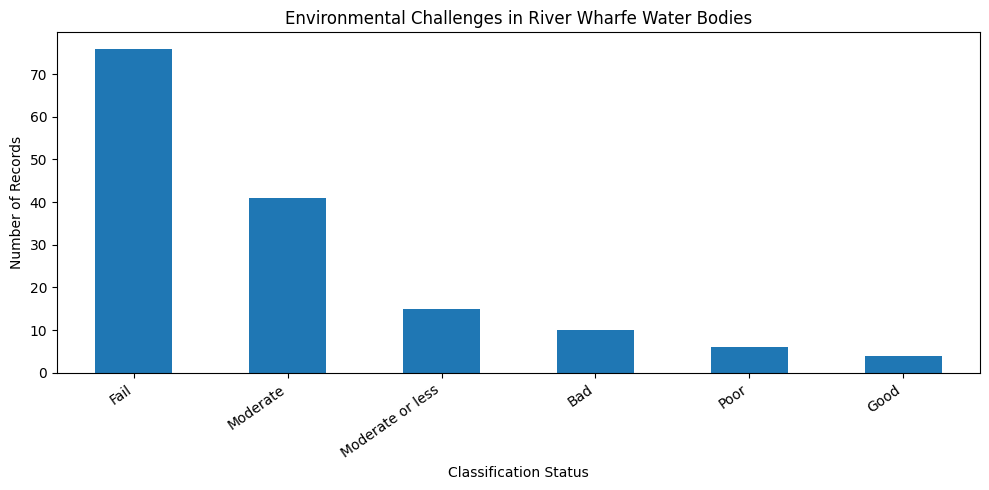

In [ ]:

import matplotlib.pyplot as plt

df = filtered["challenges"].copy()

summary = (
    df["Classification Status"]
    .fillna("Unknown")
    .value_counts()
)

plt.figure(figsize=(10, 5))
summary.plot(kind="bar")

plt.title("Environmental Challenges in River Wharfe Water Bodies")
plt.xlabel("Classification Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("wharfe_challenges.png", dpi=300)
plt.show()


In [ ]:

from google.colab import files

files.download("wharfe_kg.ttl")
files.download("wharfe_challenges.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Total RDF triples:", len(g))

print("\nSample RDF triples:")
for triple in list(g)[:10]:
    print(triple)

Total RDF triples: 210021

Sample RDF triples:
(rdflib.term.URIRef('https://example.org/wharfe/classifications_1268109'), rdflib.term.URIRef('https://example.org/wharfe/River_Basin_District'), rdflib.term.Literal('Humber'))
(rdflib.term.URIRef('https://example.org/wharfe/classifications_766811'), rdflib.term.URIRef('https://example.org/wharfe/Operational_Catchment'), rdflib.term.Literal('Wharfe Middle and Washburn'))
(rdflib.term.URIRef('https://example.org/wharfe/classifications_698132'), rdflib.term.URIRef('https://example.org/wharfe/Water_Body_ID'), rdflib.term.Literal('GB104027064255'))
(rdflib.term.URIRef('https://example.org/wharfe/objectives_151589'), rdflib.term.URIRef('https://example.org/wharfe/Water_Body'), rdflib.term.Literal('Skirfare from Cowside Beck to River Wharfe'))
(rdflib.term.URIRef('https://example.org/wharfe/objectives_90950'), rdflib.term.URIRef('http://purl.org/dc/terms/source'), rdflib.term.Literal('England_objectives.csv'))
(rdflib.term.URIRef('https://exampl

In [ ]:

from google.colab import files

files.download("wharfe_kg.ttl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from rdflib import Graph

g = Graph()
g.parse("wharfe_kg.ttl", format="turtle")

print("Total RDF triples:", len(g))

query = """
PREFIX ex: <https://example.org/wharfe/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?waterbody ?label
WHERE {
    ?waterbody a ex:RiverWaterBody ;
               rdfs:label ?label .
}
ORDER BY ?label
"""

results = list(g.query(query))

print("Number of river water bodies:", len(results))

for row in results[:20]:
    print(row.label)


Total RDF triples: 210021
Number of river water bodies: 30
Barben Beck/River Dibb Catchment (trib of Wharfe)
Barden Beck Catchment (trib of Wharfe)
Cock Beck Catchment (trib of Wharfe)
Collingham Bk Catchment (trib of Wharfe)
Dorts Dike  Catchment (trib of Wharfe)
Fir Beck/Blands Beck Catchment (trib of Wharfe)
Green Field Beck from Source to River Wharfe
Hambleton Beck/Ings Bk Catch (trib of Wharfe)
Hebden Beck Catchment (trib of Wharfe)
Kex Beck Catchment (trib of Wharfe)
Linton Beck Catchament (Trib of Wharfe)
Oughtershaw Beck from Source to River Wharfe
Ouse Still/fleet bk - Kelfield and Wharfe d/s Ryther
Ouse from R Wharfe to Upper Humber
Park Gill Beck from Source to River Wharfe
Riffa Beck/West Beck Catch (trib of Wharfe)
Skirfare from Cowside Beck to River Wharfe
Stank Beck catchment (trib of Wharfe)
The Fleet/The Foss from Source to R Wharfe
The Foss Catchment (trib of Wharfe)


In [ ]:

query = """
PREFIX ex: <https://example.org/wharfe/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?waterbody ?name
WHERE {
    ?waterbody a ex:RiverWaterBody ;
               rdfs:label ?name .

    FILTER(
        STRSTARTS(LCASE(STR(?name)), "wharfe")
    )
}
ORDER BY ?name
"""

results = list(g.query(query))

print("Main River Wharfe water bodies:\n")

for row in results:
    print(str(row.waterbody).split("/")[-1],
          "|", row.name)

print("\nTotal:", len(results))


Main River Wharfe water bodies:

GB104027064257 | Wharfe from Barben Beck/River Dibb to Hundwith Beck
GB104027064255 | Wharfe from Collingham Beck to Tadcaster Weir
GB104027064258 | Wharfe from Hundwith Beck to River Washburn
GB104027069290 | Wharfe from Oughtershaw Beck to Park Gill Beck
GB104027064253 | Wharfe from Park Gill Bk to Barben Beck/River Dibb
GB104027064254 | Wharfe from R Washburn to Collingham Beck
GB104027064256 | Wharfe from Tadcaster Weir to River Ouse

Total: 7


In [ ]:

from rdflib import Graph, Namespace, RDF, RDFS

EX = Namespace("https://example.org/wharfe/")

# Water bodies dipilih untuk kajian awal
selected_ids = [
    "GB104027064257",
    "GB104027064258",
    "GB104027064254"
]

# Membina subgraph baharu
study_graph = Graph()

for prefix, namespace in g.namespaces():
    study_graph.bind(prefix, namespace)

for water_id in selected_ids:
    water_uri = EX[water_id]

    # Simpan maklumat water body
    for triple in g.triples((water_uri, None, None)):
        study_graph.add(triple)

    # Simpan rekod yang dikaitkan
    for record in g.objects(water_uri, EX.hasRecord):
        for triple in g.triples((record, None, None)):
            study_graph.add(triple)

study_graph.serialize(
    destination="wharfe_study_kg.ttl",
    format="turtle"
)

print("Selected water bodies:", len(selected_ids))
print("Study RDF triples:", len(study_graph))


Selected water bodies: 3
Study RDF triples: 17223


In [ ]:
from google.colab import files
files.download("wharfe_study_kg.ttl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import DCTERMS, XSD

EX = Namespace("https://example.org/wharfe/")
PROV = Namespace("http://www.w3.org/ns/prov#")

# Baca Knowledge Graph asal
source_graph = Graph()
source_graph.parse("wharfe_kg.ttl", format="turtle")

# Lima water bodies daripada Table 4-3
selected_ids = [
    "GB104027064257",
    "GB104027064258",
    "GB104027064254",
    "GB104027064255",
    "GB104027064256"
]

kg = Graph()

for prefix, ns in source_graph.namespaces():
    kg.bind(prefix, ns)

kg.bind("prov", PROV)

# Salin water body dan rekod berkaitan
for water_id in selected_ids:
    water = EX[water_id]

    for triple in source_graph.triples((water, None, None)):
        kg.add(triple)

    for record in source_graph.objects(water, EX.hasRecord):
        for triple in source_graph.triples((record, None, None)):
            kg.add(triple)

# Daftarkan dokumen penilaian
report = EX.Lobwood_EAR_2025
permit = EX.Lobwood_Drought_Option_2025
reach = EX.Wharfe1

report_url = URIRef(
    "https://www.yorkshirewater.com/media/e5sj2vb5/"
    "yw-dp-wharfe-at-lobwood-ear_main-ear.pdf"
)

kg.add((report, RDF.type, EX.EnvironmentalAssessmentReport))
kg.add((report, DCTERMS.source, report_url))
kg.add((report, DCTERMS.date, Literal("2025-06-12", datatype=XSD.date)))

kg.add((permit, RDF.type, EX.DroughtPermitOption))
kg.add((permit, EX.hasAssessment, report))
kg.add((permit, EX.hasAssessedReach, reach))

kg.add((reach, RDF.type, EX.RiverReach))
kg.add((reach, RDFS.label, Literal("Wharfe 1: Lobwood to Ulleskelf")))

for water_id in selected_ids:
    kg.add((reach, EX.includesAssessedWaterBody, EX[water_id]))

# Ramalan daripada Table 5-1, PDF halaman 18
predictions = [
    ("River flow", "Summer/Autumn", "Moderate"),
    ("River flow", "Winter", "Minor"),
    ("River habitat", "Not specified", "Moderate"),
    ("Water quality", "Not specified", "Moderate")
]

for i, (component, season, impact) in enumerate(predictions, 1):
    node = EX[f"Lobwood_Prediction_{i}"]

    kg.add((node, RDF.type, EX.PredictedEnvironmentalImpact))
    kg.add((node, EX.environmentalComponent, Literal(component)))
    kg.add((node, EX.season, Literal(season)))
    kg.add((node, EX.predictedSeverity, Literal(impact)))
    kg.add((node, PROV.wasDerivedFrom, report))
    kg.add((node, EX.sourcePdfPage, Literal(18, datatype=XSD.integer)))
    kg.add((reach, EX.hasPredictedImpact, node))

# Simpan fail RDF/Turtle
kg.serialize(
    destination="wharfe_permit_kg.ttl",
    format="turtle"
)

print("Water bodies:", len(selected_ids))
print("Total RDF triples:", len(kg))
print("Predictions added:", len(predictions))
print("File created: wharfe_permit_kg.ttl")


Water bodies: 5
Total RDF triples: 32197
Predictions added: 4
File created: wharfe_permit_kg.ttl


In [ ]:

query = """
PREFIX ex: <https://example.org/wharfe/>

SELECT ?component ?season ?impact
WHERE {
    ex:Wharfe1 ex:hasPredictedImpact ?prediction .

    ?prediction
        ex:environmentalComponent ?component ;
        ex:season ?season ;
        ex:predictedSeverity ?impact .
}
ORDER BY ?component ?season
"""

for row in kg.query(query):
    print(
        str(row.component),
        "|", str(row.season),
        "|", str(row.impact)
    )


River flow | Summer/Autumn | Moderate
River flow | Winter | Minor
River habitat | Not specified | Moderate
Water quality | Not specified | Moderate


In [ ]:
from google.colab import files

files.download("wharfe_permit_kg.ttl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from rdflib import Graph
from rdflib.namespace import RDF
from collections import Counter

g = Graph()
g.parse("wharfe_permit_kg.ttl", format="turtle")

types = Counter(
    str(object_).split("/")[-1]
    for _, _, object_ in g.triples((None, RDF.type, None))
)

print("Total RDF triples:", len(g))

print("\nEntities by type:")
for entity_type, count in types.most_common():
    print(f"{entity_type}: {count}")


Total RDF triples: 32197

Entities by type:
Classification: 1237
Objective: 234
Challenge: 28
ProtectedAreaLink: 15
RiverWaterBody: 5
PredictedEnvironmentalImpact: 4
DroughtPermitOption: 1
RiverReach: 1
EnvironmentalAssessmentReport: 1


In [ ]:

import pandas as pd
from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import XSD, DCTERMS

# 1. Baca Knowledge Graph sedia ada
kg = Graph()
kg.parse("wharfe_permit_kg.ttl", format="turtle")

# 2. Baca data sebenar Addingham
df = pd.read_csv("Addingham-flow-daily-Qualified.csv")
df["date"] = pd.to_datetime(df["date"])
df["value"] = pd.to_numeric(df["value"], errors="coerce")

EX = Namespace("https://example.org/wharfe/")
SOSA = Namespace("http://www.w3.org/ns/sosa/")
QUDT = Namespace("http://qudt.org/schema/qudt/")

kg.bind("ex", EX)
kg.bind("sosa", SOSA)
kg.bind("qudt", QUDT)

# 3. Daftarkan stesen dan parameter
station = EX.AddinghamFlowGauge
parameter = EX.RiverDischarge
location = EX.AddinghamRiverLocation

kg.add((station, RDF.type, SOSA.Sensor))
kg.add((station, RDFS.label, Literal("Addingham flow gauge")))
kg.add((parameter, RDFS.label, Literal("River discharge")))
kg.add((location, RDF.type, SOSA.FeatureOfInterest))

# 4. Tambah setiap rekod sebagai SOSA Observation
for _, row in df.dropna(subset=["date", "value"]).iterrows():
    date = row["date"].strftime("%Y-%m-%d")
    obs = EX[f"AddinghamFlow_{date}"]

    kg.add((obs, RDF.type, SOSA.Observation))
    kg.add((obs, SOSA.madeBySensor, station))
    kg.add((obs, SOSA.observedProperty, parameter))
    kg.add((obs, SOSA.hasFeatureOfInterest, location))
    kg.add((obs, SOSA.phenomenonTime,
            Literal(date, datatype=XSD.date)))
    kg.add((obs, SOSA.hasSimpleResult,
            Literal(float(row["value"]), datatype=XSD.double)))
    kg.add((obs, QUDT.unit,
            URIRef("http://qudt.org/vocab/unit/M3-PER-SEC")))

    # Asal usul rekod
    kg.add((obs, DCTERMS.source,
            Literal("Addingham-flow-daily-Qualified.csv")))

# 5. Simpan Knowledge Graph baharu
kg.serialize(
    "wharfe_kg_with_flow.ttl",
    format="turtle"
)

print("Flow observations:", len(df))
print("Total RDF triples:", len(kg))
print("Saved: wharfe_kg_with_flow.ttl")


FileNotFoundError: [Errno 2] No such file or directory: 'Addingham-flow-daily-Qualified.csv'

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["value"], linewidth=1)
plt.axhline(
    252 / 86.4,
    linestyle="--",
    label="252 Ml/day threshold"
)
plt.axvline(
    pd.Timestamp("2025-08-22"),
    linestyle=":",
    label="Permit approval date"
)

plt.title("Daily River Discharge at Addingham (2025–2026)")
plt.xlabel("Date")
plt.ylabel("Discharge (m³/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("addingham_flow_2025_2026.png", dpi=300)
plt.show()


KeyError: 'date'

<Figure size 1200x500 with 0 Axes>

In [ ]:
from google.colab import files

files.download("wharfe_kg_with_flow.ttl")
files.download("addingham_flow_2025_2026.png")

FileNotFoundError: Cannot find file: wharfe_kg_with_flow.ttl

In [ ]:

from google.colab import files

uploaded = files.upload()


KeyboardInterrupt: 

In [ ]:

from google.colab import files

uploaded = files.upload()


KeyboardInterrupt: 

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'Addingham-flow-daily-Qualified.csv', 'sample_data']


In [ ]:
import os

print(os.listdir("/content"))


['.config', 'wharfe_kg.ttl', 'Addingham-flow-daily-Qualified.csv', 'sample_data']


In [ ]:

from rdflib import Graph

g = Graph()
g.parse("/content/wharfe_kg.ttl", format="turtle")

print("Total RDF triples:", len(g))


ModuleNotFoundError: No module named 'rdflib'

In [ ]:

%pip install rdflib pandas matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 13.1 MB/s  0:00:00


In [ ]:

from rdflib import Graph

g = Graph()
g.parse("/content/wharfe_kg.ttl", format="turtle")

print("Total RDF triples:", len(g))


Total RDF triples: 210021


In [ ]:
# Lima water bodies daripada Table 4-3
selected_ids = [
    "GB104027064257",
    "GB104027064258",
    "GB104027064254",
    "GB104027064255",
    "GB104027064256"
]

In [ ]:

from rdflib import Graph

kg = Graph()
kg.parse("wharfe_permit_kg.ttl", format="turtle")

print("Total RDF triples:", len(kg))


FileNotFoundError: [Errno 2] No such file or directory: '/wharfe_permit_kg.ttl'

In [ ]:

from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import DCTERMS, XSD

EX = Namespace("https://example.org/wharfe/")
PROV = Namespace("http://www.w3.org/ns/prov#")

# Baca Knowledge Graph asal
source_graph = Graph()
source_graph.parse("/content/wharfe_kg.ttl", format="turtle")

# Lima water bodies daripada Environmental Assessment Report
selected_ids = [
    "GB104027064257",
    "GB104027064258",
    "GB104027064254",
    "GB104027064255",
    "GB104027064256"
]

kg = Graph()

for prefix, namespace in source_graph.namespaces():
    kg.bind(prefix, namespace)

kg.bind("prov", PROV)

# Salin data lima water bodies
for water_id in selected_ids:
    water = EX[water_id]

    for triple in source_graph.triples((water, None, None)):
        kg.add(triple)

    for record in source_graph.objects(water, EX.hasRecord):
        for triple in source_graph.triples((record, None, None)):
            kg.add(triple)

# Tambah Drought Permit dan Environmental Assessment Report
report = EX.Lobwood_EAR_2025
permit = EX.Lobwood_Drought_Option_2025
reach = EX.Wharfe1

kg.add((report, RDF.type, EX.EnvironmentalAssessmentReport))
kg.add((report, DCTERMS.date,
        Literal("2025-06-12", datatype=XSD.date)))

kg.add((report, DCTERMS.source, URIRef(
    "https://www.yorkshirewater.com/media/e5sj2vb5/"
    "yw-dp-wharfe-at-lobwood-ear_main-ear.pdf"
)))

kg.add((permit, RDF.type, EX.DroughtPermitOption))
kg.add((permit, EX.hasAssessment, report))
kg.add((permit, EX.hasAssessedReach, reach))

kg.add((reach, RDF.type, EX.RiverReach))
kg.add((reach, RDFS.label,
        Literal("Wharfe 1: Lobwood to Ulleskelf")))

for water_id in selected_ids:
    kg.add((reach, EX.includesAssessedWaterBody, EX[water_id]))

# Ramalan daripada Environmental Assessment Report
predictions = [
    ("River flow", "Summer/Autumn", "Moderate"),
    ("River flow", "Winter", "Minor"),
    ("River habitat", "Not specified", "Moderate"),
    ("Water quality", "Not specified", "Moderate")
]

for i, (component, season, impact) in enumerate(predictions, 1):
    node = EX[f"Lobwood_Prediction_{i}"]

    kg.add((node, RDF.type, EX.PredictedEnvironmentalImpact))
    kg.add((node, EX.environmentalComponent, Literal(component)))
    kg.add((node, EX.season, Literal(season)))
    kg.add((node, EX.predictedSeverity, Literal(impact)))
    kg.add((node, PROV.wasDerivedFrom, report))
    kg.add((node, EX.sourcePdfPage,
            Literal(18, datatype=XSD.integer)))
    kg.add((reach, EX.hasPredictedImpact, node))

# Simpan fail baharu
kg.serialize(
    destination="/content/wharfe_permit_kg.ttl",
    format="turtle"
)

print("SUCCESS!")
print("Total RDF triples:", len(kg))
print("File created: wharfe_permit_kg.ttl")


SUCCESS!
Total RDF triples: 32197
File created: wharfe_permit_kg.ttl


In [ ]:
from google.colab import files

files.download("wharfe_permit_kg.ttl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import DCTERMS, XSD

# 1. Baca Knowledge Graph permit
kg = Graph()
kg.parse("/content/wharfe_permit_kg.ttl", format="turtle")

# 2. Baca data Addingham
df = pd.read_csv(
    "/content/Addingham-flow-daily-Qualified.csv"
)

df["date"] = pd.to_datetime(df["date"])
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# 3. Definisikan namespace
EX = Namespace("https://example.org/wharfe/")
SOSA = Namespace("http://www.w3.org/ns/sosa/")
QUDT_UNIT = Namespace("http://qudt.org/vocab/unit/")

kg.bind("ex", EX)
kg.bind("sosa", SOSA)
kg.bind("unit", QUDT_UNIT)

# 4. Daftarkan stesen dan parameter
station = EX.AddinghamFlowGauge
parameter = EX.RiverDischarge
river_location = EX.AddinghamRiverLocation

kg.add((station, RDF.type, SOSA.Sensor))
kg.add((station, RDFS.label, Literal("Addingham flow gauge")))
kg.add((parameter, RDF.type, SOSA.ObservableProperty))
kg.add((parameter, RDFS.label, Literal("River discharge")))
kg.add((river_location, RDF.type, SOSA.FeatureOfInterest))

# 5. Tambah semua pemerhatian
valid_df = df.dropna(subset=["date", "value"])

for _, row in valid_df.iterrows():
    date = row["date"].strftime("%Y-%m-%d")

    observation = EX[f"AddinghamFlow_{date}"]

    kg.add((observation, RDF.type, SOSA.Observation))
    kg.add((observation, SOSA.madeBySensor, station))
    kg.add((observation, SOSA.observedProperty, parameter))
    kg.add((observation, SOSA.hasFeatureOfInterest, river_location))
    kg.add((observation, SOSA.phenomenonTime,
            Literal(date, datatype=XSD.date)))
    kg.add((observation, SOSA.hasSimpleResult,
            Literal(float(row["value"]), datatype=XSD.double)))
    kg.add((observation, EX.unit, QUDT_UNIT["M3-PER-SEC"]))
    kg.add((observation, DCTERMS.source,
            Literal("Addingham-flow-daily-Qualified.csv")))

    # Simpan penunjuk kualiti rekod
    kg.add((observation, EX.dataQuality,
            Literal(str(row["quality"]))))
    kg.add((observation, EX.dataCompleteness,
            Literal(str(row["completeness"]))))

# 6. Simpan Knowledge Graph Version 2.0
kg.serialize(
    "/content/wharfe_kg_v2.ttl",
    format="turtle"
)

print("SUCCESS!")
print("Flow observations:", len(valid_df))
print("Total RDF triples:", len(kg))
print("Saved: wharfe_kg_v2.ttl")


SUCCESS!
Flow observations: 418
Total RDF triples: 36382
Saved: wharfe_kg_v2.ttl


In [ ]:

query = """
PREFIX sosa: <http://www.w3.org/ns/sosa/>

SELECT (COUNT(?obs) AS ?total)
WHERE {
    ?obs a sosa:Observation .
}
"""

for row in kg.query(query):
    print("Total SOSA observations:", row.total)


Total SOSA observations: 418


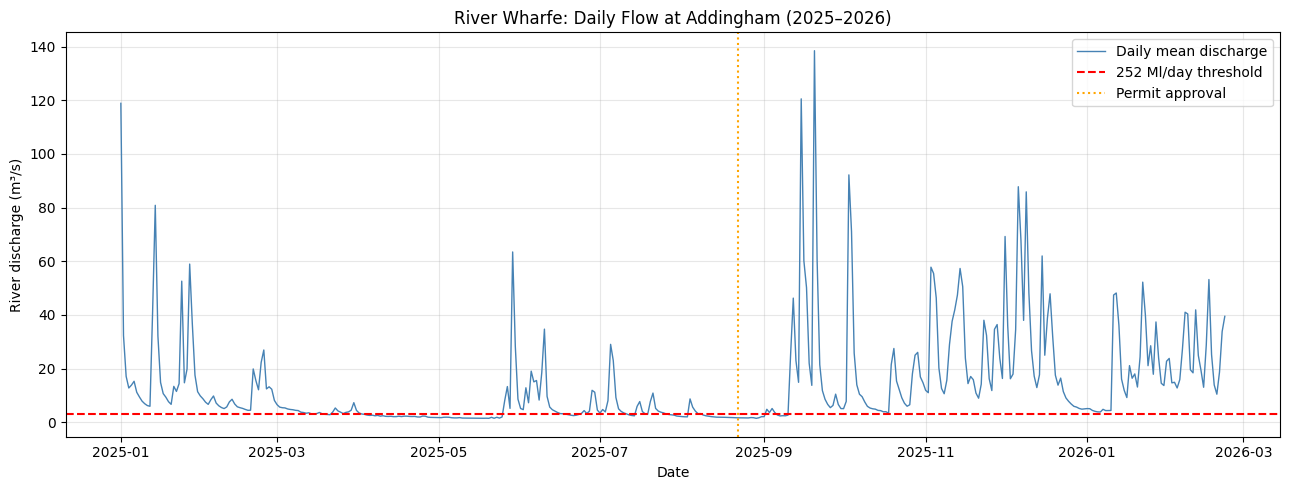

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    df["date"],
    df["value"],
    color="steelblue",
    linewidth=1,
    label="Daily mean discharge"
)

plt.axhline(
    y=252/86.4,
    color="red",
    linestyle="--",
    label="252 Ml/day threshold"
)

plt.axvline(
    x=pd.Timestamp("2025-08-22"),
    color="orange",
    linestyle=":",
    label="Permit approval"
)

plt.title("River Wharfe: Daily Flow at Addingham (2025–2026)")
plt.xlabel("Date")
plt.ylabel("River discharge (m³/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/addingham_flow_analysis.png",
    dpi=300
)

plt.show()


In [ ]:
from google.colab import files

files.download("wharfe_kg_v2.ttl")
files.download("addingham_flow_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

df = pd.read_csv("/content/Addingham-flow-daily-Qualified.csv")

df["date"] = pd.to_datetime(df["date"])
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# Dua tempoh yang sama panjang
before = df[
    (df["date"] >= "2025-05-22") &
    (df["date"] < "2025-08-22")
]

after = df[
    (df["date"] >= "2025-08-22") &
    (df["date"] <= "2025-11-21")
]

threshold = 252 / 86.4

summary = pd.DataFrame({
    "Period": ["Before approval", "After approval"],
    "Days": [len(before), len(after)],
    "Mean flow (m3/s)": [
        before["value"].mean(),
        after["value"].mean()
    ],
    "Minimum flow (m3/s)": [
        before["value"].min(),
        after["value"].min()
    ],
    "Days below threshold": [
        (before["value"] < threshold).sum(),
        (after["value"] < threshold).sum()
    ]
})

print(summary.to_string(index=False))

summary.to_csv(
    "/content/addingham_flow_summary.csv",
    index=False
)


         Period  Days  Mean flow (m3/s)  Minimum flow (m3/s)  Days below threshold
Before approval    92          6.560033                1.477                    33
 After approval    92         19.482217                1.447                    16


In [ ]:

from rdflib import Graph
import pandas as pd

kg = Graph()
kg.parse("/content/wharfe_kg_v2.ttl", format="turtle")

query = """
PREFIX ex: <https://example.org/wharfe/>
PREFIX sosa: <http://www.w3.org/ns/sosa/>

SELECT ?date ?flow
WHERE {
    ?obs a sosa:Observation ;
         sosa:madeBySensor ex:AddinghamFlowGauge ;
         sosa:observedProperty ex:RiverDischarge ;
         sosa:phenomenonTime ?date ;
         sosa:hasSimpleResult ?flow .
}
ORDER BY ?date
"""

results = list(kg.query(query))

flow_sparql = pd.DataFrame(
    [(str(r.date), float(r.flow)) for r in results],
    columns=["Date", "Flow_m3s"]
)

print("Observations retrieved:", len(flow_sparql))
print(flow_sparql.head(10))

flow_sparql.to_csv(
    "/content/addingham_sparql_results.csv",
    index=False
)


Observations retrieved: 418
         Date  Flow_m3s
0  2025-01-01   118.856
1  2025-01-02    32.318
2  2025-01-03    17.097
3  2025-01-04    12.749
4  2025-01-05    13.827
5  2025-01-06    15.261
6  2025-01-07    11.171
7  2025-01-08     9.450
8  2025-01-09     7.878
9  2025-01-10     6.908


In [ ]:

from google.colab import files

files.download("addingham_flow_summary.csv")
files.download("addingham_sparql_results.csv")
files.download("wharfe_kg_v2.ttl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'wharfe_kg.ttl', 'observations-2026-10-31T15_55_5.csv', 'addingham_flow_summary.csv', 'Addingham-flow-daily-Qualified.csv', 'wharfe_permit_kg.ttl', 'observations-2026-10-31T15_54_32.csv', 'addingham_sparql_results.csv', 'wharfe_kg_v2.ttl', 'addingham_flow_analysis.png', 'sample_data']


In [ ]:

import pandas as pd
from rdflib import Graph, Namespace, Literal, RDF, RDFS, URIRef
from rdflib.namespace import DCTERMS, XSD

# Baca Knowledge Graph Version 2.0
kg = Graph()
kg.parse("/content/wharfe_kg_v2.ttl", format="turtle")

# Baca kedua-dua CSV
files_list = [
    "/content/observations-2026-10-31T15_54_32.csv",
    "/content/observations-2026-10-31T15_55_5.csv"
]

frames = []

for filename in files_list:
    part = pd.read_csv(filename, dtype=str)
    part["source_file"] = filename.split("/")[-1]
    frames.append(part)

df = pd.concat(frames, ignore_index=True)

# Pilih air sungai sebenar sahaja
river = df[
    df["sampleMaterialType"].eq(
        "RIVER / RUNNING SURFACE WATER"
    )
].copy()

# Buang rekod duplicate berdasarkan URI asal
river = river.drop_duplicates(subset=["id"])

EX = Namespace("https://example.org/wharfe/")
SOSA = Namespace("http://www.w3.org/ns/sosa/")

kg.bind("sosa", SOSA)
kg.bind("ex", EX)

for _, row in river.iterrows():

    # Gunakan URI observation asal daripada EA
    obs = URIRef(row["id"])

    station = EX[
        "WQStation_" + row["samplingPoint.notation"]
    ]

    parameter = EX[
        "Determinand_" + row["determinand.notation"]
    ]

    kg.add((station, RDF.type, SOSA.Sensor))
    kg.add((
        station, RDFS.label,
        Literal(row["samplingPoint.prefLabel"])
    ))

    kg.add((parameter, RDF.type, SOSA.ObservableProperty))
    kg.add((
        parameter, RDFS.label,
        Literal(row["determinand.prefLabel"])
    ))

    kg.add((obs, RDF.type, SOSA.Observation))
    kg.add((obs, SOSA.madeBySensor, station))
    kg.add((obs, SOSA.observedProperty, parameter))

    kg.add((
        obs, SOSA.phenomenonTime,
        Literal(
            row["phenomenonTime"],
            datatype=XSD.dateTime
        )
    ))

    # Simpan nilai asal termasuk tanda < bagi
    # bacaan di bawah had pengesanan
    kg.add((
        obs, SOSA.hasSimpleResult,
        Literal(row["result"])
    ))

    kg.add((
        obs, EX.measurementUnit,
        Literal(row["unit"])
    ))

    kg.add((
        obs, EX.samplingPurpose,
        Literal(row["samplingPurpose"])
    ))

    kg.add((
        obs, DCTERMS.source,
        Literal(row["source_file"])
    ))

# Simpan Version 3.0
kg.serialize(
    "/content/wharfe_kg_v3.ttl",
    format="turtle"
)

print("SUCCESS - Knowledge Graph V3!")
print("River observations:", len(river))
print("Total RDF triples:", len(kg))
print("File: wharfe_kg_v3.ttl")


SUCCESS - Knowledge Graph V3!
River observations: 238
Total RDF triples: 38326
File: wharfe_kg_v3.ttl


In [ ]:
from google.colab import files

files.download("wharfe_kg_v3.ttl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from rdflib import Graph, RDF, Namespace

kg = Graph()
kg.parse("/content/wharfe_kg_v3.ttl", format="turtle")

SOSA = Namespace("http://www.w3.org/ns/sosa/")

observations = set(
    kg.subjects(RDF.type, SOSA.Observation)
)

stations = set(
    kg.objects(None, SOSA.madeBySensor)
)

print("Total RDF triples:", len(kg))
print("Water quality observations:", len(observations))
print("Monitoring stations:", len(stations))

Total RDF triples: 38326
Water quality observations: 656
Monitoring stations: 4


In [ ]:
from rdflib import Namespace, RDF

SOSA = Namespace("http://www.w3.org/ns/sosa/")
EX = Namespace("https://example.org/wharfe/")

print("Monitoring stations:")
for station in sorted(stations, key=str):
    print("-", station)

print("\nTotal observations:", len(observations))

Monitoring stations:
- https://example.org/wharfe/AddinghamFlowGauge
- https://example.org/wharfe/WQStation_NE-49700312
- https://example.org/wharfe/WQStation_NE-49705093
- https://example.org/wharfe/WQStation_NE-RTN0011

Total observations: 656


In [ ]:
!pip -q install pyvis

In [ ]:

from pyvis.network import Network
from rdflib import RDF, RDFS, Namespace

SOSA = Namespace("http://www.w3.org/ns/sosa/")

net = Network(
    height="650px",
    width="100%",
    directed=True,
    notebook=True,
    cdn_resources="in_line"
)

# Paparkan stesen dan beberapa pemerhatian sahaja
for station in stations:
    station_id = str(station)
    name = kg.value(station, RDFS.label)
    label = str(name) if name else station_id.split("/")[-1]

    net.add_node(
        station_id,
        label=label,
        color="#2186c4",
        shape="dot",
        size=24
    )

    station_obs = list(
        kg.subjects(SOSA.madeBySensor, station)
    )[:5]

    for i, obs in enumerate(station_obs):
        obs_id = str(obs)

        net.add_node(
            obs_id,
            label=f"Observation {i+1}",
            color="#69c18f",
            shape="dot",
            size=12
        )

        net.add_edge(
            station_id,
            obs_id,
            label="made observation"
        )

net.show("wharfe_kg_visual.html")


wharfe_kg_visual.html


In [ ]:
from IPython.display import HTML, display

with open("wharfe_kg_visual.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

In [ ]:
from rdflib import RDF

EX = Namespace("https://example.org/wharfe/")

for class_name in [
    "DroughtPermitOption",
    "EnvironmentalAssessmentReport",
    "PredictedEnvironmentalImpact",
    "RiverReach",
    "RiverWaterBody"
]:
    nodes = list(kg.subjects(RDF.type, EX[class_name]))
    print(f"\n{class_name}: {len(nodes)}")

    for node in nodes[:5]:
        print(" ", node)
        for p, o in kg.predicate_objects(node):
            print("   ", p.split("/")[-1].split("#")[-1],
                  "→", str(o)[:110])


DroughtPermitOption: 1
  https://example.org/wharfe/Lobwood_Drought_Option_2025
    type → https://example.org/wharfe/DroughtPermitOption
    hasAssessedReach → https://example.org/wharfe/Wharfe1
    hasAssessment → https://example.org/wharfe/Lobwood_EAR_2025

EnvironmentalAssessmentReport: 1
  https://example.org/wharfe/Lobwood_EAR_2025
    type → https://example.org/wharfe/EnvironmentalAssessmentReport
    date → 2025-06-12
    source → https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wharfe-at-lobwood-ear_main-ear.pdf

PredictedEnvironmentalImpact: 4
  https://example.org/wharfe/Lobwood_Prediction_1
    type → https://example.org/wharfe/PredictedEnvironmentalImpact
    wasDerivedFrom → https://example.org/wharfe/Lobwood_EAR_2025
    environmentalComponent → River flow
    predictedSeverity → Moderate
    season → Summer/Autumn
    sourcePdfPage → 18
  https://example.org/wharfe/Lobwood_Prediction_2
    type → https://example.org/wharfe/PredictedEnvironmentalImpact
    wasDerived

In [ ]:
from IPython.display import HTML, display

with open("/content/wharfe_kg_visual.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

In [ ]:
from rdflib import RDF, Namespace

EX = Namespace("https://example.org/wharfe/")

classes = [
    "DroughtPermitOption",
    "EnvironmentalAssessmentReport",
    "PredictedEnvironmentalImpact",
    "RiverReach",
    "RiverWaterBody"
]

for name in classes:
    nodes = list(kg.subjects(RDF.type, EX[name]))
    print(f"{name}: {len(nodes)}")

DroughtPermitOption: 1
EnvironmentalAssessmentReport: 1
PredictedEnvironmentalImpact: 4
RiverReach: 1
RiverWaterBody: 5


In [ ]:
from rdflib import RDF, RDFS, Namespace

EX = Namespace("https://example.org/wharfe/")

classes = [
    "DroughtPermitOption",
    "EnvironmentalAssessmentReport",
    "PredictedEnvironmentalImpact",
    "RiverReach",
    "RiverWaterBody"
]

for class_name in classes:
    nodes = list(kg.subjects(RDF.type, EX[class_name]))

    print("\n" + "=" * 45)
    print(class_name)

    for node in nodes[:2]:
        print("\nENTITY:", node)

        for predicate, obj in kg.predicate_objects(node):
            if predicate == RDF.type:
                continue

            relation = str(predicate).split("/")[-1].split("#")[-1]
            print(f"  {relation} → {str(obj)[:100]}")


DroughtPermitOption

ENTITY: https://example.org/wharfe/Lobwood_Drought_Option_2025
  hasAssessedReach → https://example.org/wharfe/Wharfe1
  hasAssessment → https://example.org/wharfe/Lobwood_EAR_2025

EnvironmentalAssessmentReport

ENTITY: https://example.org/wharfe/Lobwood_EAR_2025
  date → 2025-06-12
  source → https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wharfe-at-lobwood-ear_main-ear.pdf

PredictedEnvironmentalImpact

ENTITY: https://example.org/wharfe/Lobwood_Prediction_1
  wasDerivedFrom → https://example.org/wharfe/Lobwood_EAR_2025
  environmentalComponent → River flow
  predictedSeverity → Moderate
  season → Summer/Autumn
  sourcePdfPage → 18

ENTITY: https://example.org/wharfe/Lobwood_Prediction_2
  wasDerivedFrom → https://example.org/wharfe/Lobwood_EAR_2025
  environmentalComponent → River flow
  predictedSeverity → Minor
  season → Winter
  sourcePdfPage → 18

RiverReach

ENTITY: https://example.org/wharfe/Wharfe1
  label → Wharfe 1: Lobwood to Ulleskelf
  hasPre

In [ ]:

from pyvis.network import Network
from rdflib import RDF, RDFS, Namespace, Literal
from IPython.display import HTML, display
from collections import Counter

EX = Namespace("https://example.org/wharfe/")
SOSA = Namespace("http://www.w3.org/ns/sosa/")

net = Network(
    height="750px",
    width="100%",
    directed=True,
    cdn_resources="in_line"
)

net.barnes_hut(gravity=-5000, spring_length=170)
net.set_options("""
{
  "interaction": {"hover": true, "navigationButtons": true},
  "physics": {"stabilization": {"iterations": 200}},
  "edges": {"smooth": {"type": "dynamic"},
            "font": {"size": 10, "align": "middle"}},
  "nodes": {"font": {"size": 14}}
}
""")

added_nodes = set()

def add_node(uri, label, color, size=22, title=None):
    uri = str(uri)
    if uri not in added_nodes:
        net.add_node(
            uri, label=label, title=title or label,
            color=color, size=size, shape="dot"
        )
        added_nodes.add(uri)

def add_existing_edges(subject, predicate, label):
    for obj in kg.objects(subject, predicate):
        if str(subject) in added_nodes and str(obj) in added_nodes:
            net.add_edge(str(subject), str(obj), label=label)

# 1. Permit, report and assessed reach
permit = next(kg.subjects(RDF.type, EX.DroughtPermitOption))
report = next(kg.subjects(RDF.type, EX.EnvironmentalAssessmentReport))
reach = next(kg.subjects(RDF.type, EX.RiverReach))

add_node(permit, "Lobwood Drought Permit", "#d97706", 40)
add_node(report, "Environmental Assessment", "#8b5cf6", 30)
add_node(reach, "Wharfe 1: Lobwood to Ulleskelf", "#2563eb", 35)

add_existing_edges(permit, EX.hasAssessment, "hasAssessment")
add_existing_edges(permit, EX.hasAssessedReach, "hasAssessedReach")

# 2. Four predicted impacts
predictions = list(
    kg.subjects(RDF.type, EX.PredictedEnvironmentalImpact)
)

for i, prediction in enumerate(predictions, 1):
    component = kg.value(prediction, EX.environmentalComponent)
    severity = kg.value(prediction, EX.predictedSeverity)
    season = kg.value(prediction, EX.season)

    label = f"{component or 'Impact'}: {severity or 'N/A'}"
    title = f"{label}\nSeason: {season or 'Not specified'}"

    add_node(prediction, label, "#f59e0b", 25, title)
    add_existing_edges(prediction, EX.wasDerivedFrom, "wasDerivedFrom")

add_existing_edges(reach, EX.hasPredictedImpact, "hasPredictedImpact")

# 3. Five assessed river water bodies
bodies = list(kg.subjects(RDF.type, EX.RiverWaterBody))

for body in bodies:
    label = str(body).split("/")[-1]
    full_name = kg.value(body, RDFS.label)
    add_node(body, label, "#0891b2", 24,
             str(full_name) if full_name else label)

add_existing_edges(
    reach, EX.includesAssessedWaterBody,
    "includesAssessedWaterBody"
)

# 4. Monitoring stations and example observations
monitoring_stations = set(
    kg.objects(None, SOSA.madeBySensor)
)

for station in monitoring_stations:
    name = kg.value(station, RDFS.label)
    label = str(name) if name else str(station).split("/")[-1]

    if len(label) > 36:
        label = label[:33] + "..."

    station_obs = sorted(
        set(kg.subjects(SOSA.madeBySensor, station)),
        key=str
    )

    add_node(
        station, label, "#16a34a", 30,
        f"{name or label}\nObservations: {len(station_obs)}"
    )

    # Only 2 example observations per station
    for obs in station_obs[:2]:
        obs_label = "Observation"
        date = kg.value(obs, SOSA.phenomenonTime)
        value = kg.value(obs, SOSA.hasSimpleResult)

        if date:
            obs_label = str(date)[:10]

        add_node(
            obs, obs_label, "#86efac", 12,
            f"Date: {date}\nValue: {value}"
        )

        # Actual RDF direction: observation -> station
        net.add_edge(
            str(obs), str(station),
            label="madeBySensor"
        )

# Export and display
output = "/content/wharfe_integrated_kg.html"
net.write_html(output)

with open(output, encoding="utf-8") as f:
    display(HTML(f.read()))

print("Integrated Knowledge Graph created!")
print("Visual nodes:", len(added_nodes))
print("Saved:", output)


Integrated Knowledge Graph created!
Visual nodes: 24
Saved: /content/wharfe_integrated_kg.html


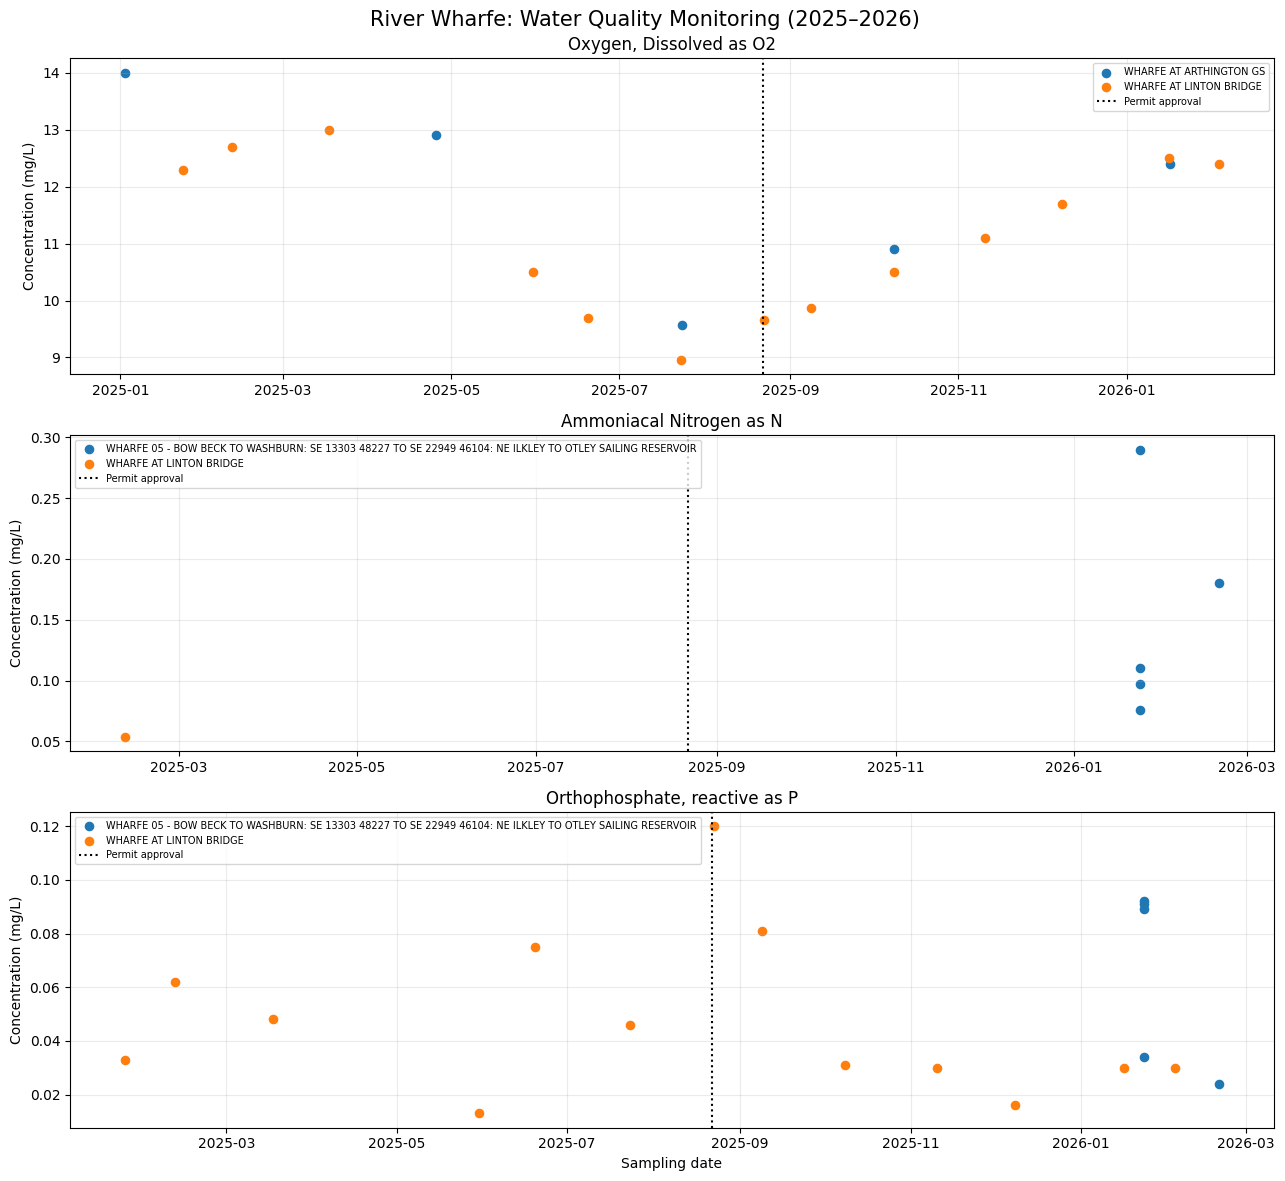

Figure 3 saved successfully.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Baca kedua-dua CSV
files_list = [
    "/content/observations-2026-10-31T15_54_32.csv",
    "/content/observations-2026-10-31T15_55_5.csv"
]

df = pd.concat(
    [pd.read_csv(f, dtype=str) for f in files_list],
    ignore_index=True
)

# Hanya sampel air sungai
df = df[
    df["sampleMaterialType"] ==
    "RIVER / RUNNING SURFACE WATER"
].copy()

df = df.drop_duplicates(subset="id")
df["date"] = pd.to_datetime(df["phenomenonTime"])

# Pilih parameter dan kekalkan unit yang sama
parameters = [
    "Oxygen, Dissolved as O2",
    "Ammoniacal Nitrogen as N",
    "Orthophosphate, reactive as P"
]

fig, axes = plt.subplots(3, 1, figsize=(13, 12))

for ax, parameter in zip(axes, parameters):

    subset = df[df["determinand.prefLabel"] == parameter].copy()

    # Asingkan bacaan bertanda < (below reporting limit)
    subset = subset[
        ~subset["result"].str.startswith("<", na=False)
    ].copy()

    subset["value"] = pd.to_numeric(
        subset["result"], errors="coerce"
    )
    subset = subset.dropna(subset=["value"])

    for station, group in subset.groupby("samplingPoint.prefLabel"):

        group = group.sort_values("date")

        # Scatter, bukan garis bersambung kerana
        # tarikh pensampelan tidak semestinya berterusan
        ax.scatter(
            group["date"],
            group["value"],
            label=station,
            s=35
        )

    ax.axvline(
        pd.Timestamp("2025-08-22"),
        linestyle=":",
        color="black",
        label="Permit approval"
    )

    ax.set_title(parameter)
    ax.set_ylabel("Concentration (mg/L)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, loc="best")

axes[-1].set_xlabel("Sampling date")

fig.suptitle(
    "River Wharfe: Water Quality Monitoring (2025–2026)",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "/content/Figure_3_Wharfe_Water_Quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully.")


In [ ]:
from google.colab import files

files.download(
    "/content/Figure_3_Wharfe_Water_Quality.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
query = """
PREFIX ex: <https://example.org/wharfe/>

SELECT ?component ?severity ?season
WHERE {
    ?impact a ex:PredictedEnvironmentalImpact ;
            ex:environmentalComponent ?component ;
            ex:predictedSeverity ?severity .
    OPTIONAL { ?impact ex:season ?season }
}
ORDER BY ?component ?season
"""

results = kg.query(query)

for row in results:
    print(
        "Component:", row.component,
        "| Severity:", row.severity,
        "| Season:", row.season
    )

Component: River flow | Severity: Moderate | Season: Summer/Autumn
Component: River flow | Severity: Minor | Season: Winter
Component: River habitat | Severity: Moderate | Season: Not specified
Component: Water quality | Severity: Moderate | Season: Not specified


In [ ]:
query_cq2 = """
PREFIX ex: <https://example.org/wharfe/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?waterBody ?name
WHERE {
    ?reach a ex:RiverReach ;
           ex:includesAssessedWaterBody ?waterBody .

    ?waterBody rdfs:label ?name .
}
ORDER BY ?waterBody
"""

results_cq2 = list(kg.query(query_cq2))

print("CQ2 - Assessed River Water Bodies")
print("Total water bodies:", len(results_cq2))

for row in results_cq2:
    waterbody_id = str(row.waterBody).split("/")[-1]
    print(waterbody_id, "|", row.name)

CQ2 - Assessed River Water Bodies
Total water bodies: 5
GB104027064254 | Wharfe from R Washburn to Collingham Beck
GB104027064255 | Wharfe from Collingham Beck to Tadcaster Weir
GB104027064256 | Wharfe from Tadcaster Weir to River Ouse
GB104027064257 | Wharfe from Barben Beck/River Dibb to Hundwith Beck
GB104027064258 | Wharfe from Hundwith Beck to River Washburn


In [ ]:
query_cq3 = """
PREFIX sosa: <http://www.w3.org/ns/sosa/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?station ?name (COUNT(DISTINCT ?obs) AS ?total)
WHERE {
    ?obs a sosa:Observation ;
         sosa:madeBySensor ?station .

    OPTIONAL { ?station rdfs:label ?name }
}
GROUP BY ?station ?name
ORDER BY DESC(?total)
"""

results_cq3 = list(kg.query(query_cq3))

print("CQ3 - Environmental Monitoring Observations")
print("-" * 60)

total = 0

for row in results_cq3:
    name = str(row.name) if row.name else str(row.station).split("/")[-1]
    count = int(row.total)
    total += count
    print(f"{name}: {count} observations")

print("-" * 60)
print("TOTAL:", total)

CQ3 - Environmental Monitoring Observations
------------------------------------------------------------
Addingham flow gauge: 418 observations
WHARFE AT LINTON BRIDGE: 168 observations
WHARFE 05 - BOW BECK TO WASHBURN: SE 13303 48227 TO SE 22949 46104: NE ILKLEY TO OTLEY SAILING RESERVOIR: 45 observations
WHARFE AT ARTHINGTON GS: 25 observations
------------------------------------------------------------
TOTAL: 656


In [ ]:
query_cq4 = """
PREFIX ex: <https://example.org/wharfe/>
PREFIX prov: <http://www.w3.org/ns/prov#>
PREFIX dct: <http://purl.org/dc/terms/>

SELECT ?impact ?component ?severity ?report ?source
WHERE {
    ?impact a ex:PredictedEnvironmentalImpact ;
            ex:environmentalComponent ?component ;
            ex:predictedSeverity ?severity ;
            prov:wasDerivedFrom ?report .

    OPTIONAL { ?report dct:source ?source }
}
ORDER BY ?component
"""

results_cq4 = list(kg.query(query_cq4))

print("CQ4 - Evidence Provenance")
print("-" * 65)

for row in results_cq4:
    print("Impact:", row.component)
    print("Severity:", row.severity)
    print("Report:", row.report)
    print("Source:", row.source)
    print("-" * 65)

print("Total traceable impacts:", len(results_cq4))

CQ4 - Evidence Provenance
-----------------------------------------------------------------
Impact: River flow
Severity: Moderate
Report: https://example.org/wharfe/Lobwood_EAR_2025
Source: https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wharfe-at-lobwood-ear_main-ear.pdf
-----------------------------------------------------------------
Impact: River flow
Severity: Minor
Report: https://example.org/wharfe/Lobwood_EAR_2025
Source: https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wharfe-at-lobwood-ear_main-ear.pdf
-----------------------------------------------------------------
Impact: River habitat
Severity: Moderate
Report: https://example.org/wharfe/Lobwood_EAR_2025
Source: https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wharfe-at-lobwood-ear_main-ear.pdf
-----------------------------------------------------------------
Impact: Water quality
Severity: Moderate
Report: https://example.org/wharfe/Lobwood_EAR_2025
Source: https://www.yorkshirewater.com/media/e5sj2vb5/yw-dp-wh

In [ ]:

from rdflib import Namespace, RDF

EX = Namespace("https://example.org/wharfe/")
SOSA = Namespace("http://www.w3.org/ns/sosa/")

# Tentukan kategori bukti berdasarkan data yang tersedia
# Ini ialah peraturan penilaian awal, bukan kesimpulan kausal.
evidence_rules = {
    "River flow": {
        "status": "Indirect evidence",
        "reason": "Addingham flow gauge is upstream of Lobwood"
    },
    "River habitat": {
        "status": "Evidence gap",
        "reason": "No direct habitat monitoring observations integrated"
    },
    "Water quality": {
        "status": "Partial evidence",
        "reason": "Water quality records exist but spatial relevance requires verification"
    }
}

print("CQ5 - Evidence Gap Assessment")
print("=" * 65)

predictions = list(
    kg.subjects(RDF.type, EX.PredictedEnvironmentalImpact)
)

for prediction in predictions:
    component = str(kg.value(
        prediction, EX.environmentalComponent
    ))
    severity = str(kg.value(
        prediction, EX.predictedSeverity
    ))

    assessment = evidence_rules.get(
        component,
        {"status": "Not assessed", "reason": "No evaluation rule"}
    )

    print("Component:", component)
    print("Predicted severity:", severity)
    print("Evidence status:", assessment["status"])
    print("Reason:", assessment["reason"])
    print("-" * 65)


CQ5 - Evidence Gap Assessment
Component: River flow
Predicted severity: Moderate
Evidence status: Indirect evidence
Reason: Addingham flow gauge is upstream of Lobwood
-----------------------------------------------------------------
Component: River flow
Predicted severity: Minor
Evidence status: Indirect evidence
Reason: Addingham flow gauge is upstream of Lobwood
-----------------------------------------------------------------
Component: River habitat
Predicted severity: Moderate
Evidence status: Evidence gap
Reason: No direct habitat monitoring observations integrated
-----------------------------------------------------------------
Component: Water quality
Predicted severity: Moderate
Evidence status: Partial evidence
Reason: Water quality records exist but spatial relevance requires verification
-----------------------------------------------------------------


In [ ]:
!pip -q install pyshacl

In [ ]:

from rdflib import Graph
from pyshacl import validate

# Load Knowledge Graph V3
data_graph = Graph()
data_graph.parse(
    "/content/wharfe_kg_v3.ttl",
    format="turtle"
)

# Define SHACL validation rules
shacl_rules = """
@prefix sh: <http://www.w3.org/ns/shacl#> .
@prefix sosa: <http://www.w3.org/ns/sosa/> .
@prefix ex: <https://example.org/wharfe/> .
@prefix prov: <http://www.w3.org/ns/prov#> .

ex:ObservationShape
    a sh:NodeShape ;
    sh:targetClass sosa:Observation ;

    sh:property [
        sh:path sosa:madeBySensor ;
        sh:minCount 1 ;
    ] ;

    sh:property [
        sh:path sosa:phenomenonTime ;
        sh:minCount 1 ;
    ] .

ex:PredictedImpactShape
    a sh:NodeShape ;
    sh:targetClass ex:PredictedEnvironmentalImpact ;

    sh:property [
        sh:path ex:environmentalComponent ;
        sh:minCount 1 ;
    ] ;

    sh:property [
        sh:path ex:predictedSeverity ;
        sh:minCount 1 ;
    ] ;

    sh:property [
        sh:path prov:wasDerivedFrom ;
        sh:minCount 1 ;
    ] .
"""

shapes_graph = Graph()
shapes_graph.parse(data=shacl_rules, format="turtle")

# Run validation
conforms, results_graph, results_text = validate(
    data_graph=data_graph,
    shacl_graph=shapes_graph,
    inference="none",
    abort_on_first=False,
    allow_infos=False,
    allow_warnings=False
)

print("SHACL VALIDATION RESULTS")
print("=" * 50)
print("Total RDF triples:", len(data_graph))
print("Conforms:", conforms)
print(results_text)


SHACL VALIDATION RESULTS
Total RDF triples: 38326
Conforms: True
Validation Report
Conforms: True



In [ ]:
with open("/content/SHACL_Validation_Report.txt", "w") as f:
    f.write("Knowledge Graph V3 SHACL Validation\n")
    f.write(f"Total RDF triples: {len(data_graph)}\n")
    f.write(results_text)

from google.colab import files
files.download("/content/SHACL_Validation_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from google.colab import files
from playwright.async_api import async_playwright

async def save_kg_png():
    html_path = Path("/content/wharfe_integrated_kg.html")

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        page = await browser.new_page(
            viewport={"width": 2200, "height": 1600},
            device_scale_factor=2
        )

        await page.goto(html_path.as_uri())
        await page.wait_for_timeout(8000)   # tunggu graph stabil

        await page.screenshot(
            path="/content/Figure_1_Wharfe_Knowledge_Graph.png",
            full_page=True
        )

        await browser.close()

await save_kg_png()
files.download("/content/Figure_1_Wharfe_Knowledge_Graph.png")

TargetClosedError: BrowserType.launch: Target page, context or browser has been closed
Browser logs:

<launching> /root/.cache/ms-playwright/chromium_headless_shell-1248/chrome-headless-shell-linux64/chrome-headless-shell --disable-field-trial-config --disable-background-networking --disable-background-timer-throttling --disable-backgrounding-occluded-windows --disable-back-forward-cache --disable-breakpad --disable-client-side-phishing-detection --disable-component-extensions-with-background-pages --disable-component-update --no-default-browser-check --disable-default-apps --disable-dev-shm-usage --disable-edgeupdater --disable-extensions --disable-features=AvoidUnnecessaryBeforeUnloadCheckSync,DestroyProfileOnBrowserClose,DialMediaRouteProvider,GlobalMediaControls,HttpsUpgrades,LensOverlay,MediaRouter,PaintHolding,ThirdPartyStoragePartitioning,BlockOriginHeaderModificationOnRedirect,AvoidCorsURLLoaderRestartOnRedirect,Translate,AutoDeElevate,OptimizationHints,NetworkTimeServiceQueryi

In [ ]:
from pathlib import Path
from google.colab import files
from playwright.async_api import async_playwright

async def save_kg_png():
    html_path = Path("/content/wharfe_integrated_kg.html")

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        page = await browser.new_page(
            viewport={"width": 2400, "height": 1800},
            device_scale_factor=2
        )

        await page.goto(html_path.as_uri(), wait_until="load")
        await page.wait_for_timeout(10000)

        await page.screenshot(
            path="/content/Figure_1_Wharfe_Knowledge_Graph.png",
            full_page=True
        )

        await browser.close()

await save_kg_png()
files.download("/content/Figure_1_Wharfe_Knowledge_Graph.png")

TargetClosedError: BrowserType.launch: Target page, context or browser has been closed
Browser logs:

<launching> /root/.cache/ms-playwright/chromium_headless_shell-1248/chrome-headless-shell-linux64/chrome-headless-shell --disable-field-trial-config --disable-background-networking --disable-background-timer-throttling --disable-backgrounding-occluded-windows --disable-back-forward-cache --disable-breakpad --disable-client-side-phishing-detection --disable-component-extensions-with-background-pages --disable-component-update --no-default-browser-check --disable-default-apps --disable-dev-shm-usage --disable-edgeupdater --disable-extensions --disable-features=AvoidUnnecessaryBeforeUnloadCheckSync,DestroyProfileOnBrowserClose,DialMediaRouteProvider,GlobalMediaControls,HttpsUpgrades,LensOverlay,MediaRouter,PaintHolding,ThirdPartyStoragePartitioning,BlockOriginHeaderModificationOnRedirect,AvoidCorsURLLoaderRestartOnRedirect,Translate,AutoDeElevate,OptimizationHints,NetworkTimeServiceQueryi

In [ ]:
!pip -q install playwright
!playwright install chromium

In [ ]:
from pathlib import Path
from google.colab import files
from playwright.async_api import async_playwright

async def save_kg_png():
    html_path = Path("/content/wharfe_integrated_kg.html")

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        page = await browser.new_page(
            viewport={"width": 2200, "height": 1600},
            device_scale_factor=2
        )

        await page.goto(html_path.as_uri())
        await page.wait_for_timeout(8000)   # tunggu graph stabil

        await page.screenshot(
            path="/content/Figure_1_Wharfe_Knowledge_Graph.png",
            full_page=True
        )

        await browser.close()

await save_kg_png()
files.download("/content/Figure_1_Wharfe_Knowledge_Graph.png")

TargetClosedError: BrowserType.launch: Target page, context or browser has been closed
Browser logs:

<launching> /root/.cache/ms-playwright/chromium_headless_shell-1248/chrome-headless-shell-linux64/chrome-headless-shell --disable-field-trial-config --disable-background-networking --disable-background-timer-throttling --disable-backgrounding-occluded-windows --disable-back-forward-cache --disable-breakpad --disable-client-side-phishing-detection --disable-component-extensions-with-background-pages --disable-component-update --no-default-browser-check --disable-default-apps --disable-dev-shm-usage --disable-edgeupdater --disable-extensions --disable-features=AvoidUnnecessaryBeforeUnloadCheckSync,DestroyProfileOnBrowserClose,DialMediaRouteProvider,GlobalMediaControls,HttpsUpgrades,LensOverlay,MediaRouter,PaintHolding,ThirdPartyStoragePartitioning,BlockOriginHeaderModificationOnRedirect,AvoidCorsURLLoaderRestartOnRedirect,Translate,AutoDeElevate,OptimizationHints,NetworkTimeServiceQueryi

In [ ]:
from google.colab import files
files.download("wharfe_integrated_kg.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install playwright
!playwright install chromium

191.1 MiB [] 0% 0.0s191.1 MiB [] 0% 269.9s191.1 MiB [] 0% 293.9s191.1 MiB [] 0% 1048.4s191.1 MiB [] 0% 865.7s191.1 MiB [] 0% 1206.2s191.1 MiB [] 0% 1060.0s191.1 MiB [] 0% 953.8s191.1 MiB [] 0% 874.2s191.1 MiB [] 0% 813.6s191.1 MiB [] 0% 826.3s191.1 MiB [] 0% 780.0s191.1 MiB [] 0% 742.4s191.1 MiB [] 0% 704.0s191.1 MiB [] 0% 676.3s191.1 MiB [] 0% 652.4s191.1 MiB [] 0% 629.8s191.1 MiB [] 0% 607.8s191.1 MiB [] 0% 588.3s191.1 MiB [] 0% 570.1s191.1 MiB [] 0% 551.3s191.1 MiB [] 0% 515.0s191.1 MiB [] 0% 484.7s191.1 MiB [] 0% 460.0s191.1 MiB [] 0% 437.1s191.1 MiB [] 0% 417.6s191.1 MiB [] 0% 400.2s191.1 MiB [] 0% 386.0s191.1 MiB [] 0% 372.2s191.1 MiB [] 0% 358.4s191.1 MiB [] 0% 344.0s191.1 MiB [] 0% 327.6s191.1 MiB [] 0% 311.5s191.1 MiB [] 0% 297.3s191.1 MiB [] 0% 284.3s191.1 MiB [] 0% 272.7s191.1 MiB [] 0% 262.5s191.1 MiB [] 0% 249.2s191.1 MiB [] 0% 236.0s191.1 MiB [] 0% 228.7s191.1 MiB [] 0% 219.3s191.1 MiB [] 0% 210.9s191.1 MiB [] 0% 203.0s191.1 MiB [] 0% 193.9s191.1 MiB [] 0% 185.7s191.1 MiB

In [ ]:
from playwright.sync_api import sync_playwright
from pathlib import Path
from google.colab import files

html_path = Path("/content/wharfe_integrated_kg.html")

with sync_playwright() as p:
    browser = p.chromium.launch(headless=True)
    page = browser.new_page(
        viewport={"width": 1800, "height": 1400},
        device_scale_factor=2
    )

    page.goto(html_path.as_uri())
    page.wait_for_timeout(5000)

    page.screenshot(
        path="/content/Figure_1_Wharfe_Knowledge_Graph.png",
        full_page=True
    )

    browser.close()

files.download("/content/Figure_1_Wharfe_Knowledge_Graph.png")

Error: It looks like you are using Playwright Sync API inside the asyncio loop.
Please use the Async API instead.

In [ ]:
from IPython.display import IFrame, display

display(IFrame("wharfe_kg_visual.html", width=1000, height=650))